# MRNet Knee MRI — EDA & Baseline

Multi-label classification of knee MRI exams from the Stanford AIMI MRNet dataset.

**Labels:** Abnormality · ACL tear · Meniscus tear  
**Data source:** Redivis (AIMI organisation)  
**Baseline model:** Frozen ResNet18 + mean slice pooling + linear 3-label head

## 1 · Setup

In [ ]:
!pip install redivis

import redivis
import os
from google.colab import userdata



In [ ]:
from google.colab import userdata

os.environ["REDIVIS_API_TOKEN"] = userdata.get("REDIVIS_API_TOKEN")
organization = redivis.organization("AIMI")
dataset = organization.dataset("mrnet_knee_mri_s:4a2c")

tables = dataset.list_tables()

Please delete the token on Redivis and remove it from your code, and follow the authentication prompts here instead.

This environment variable should only ever be set in a non-interactive environment, such as in an automated script or service.



## 2 · Dataset overview

In [ ]:
print("Available tables:")

for table in tables:
    print(table)

Available tables:
<Table aimi.mrnet_knee_mri_s:4a2c:v1_0.train_meniscus:3x4c>
<Table aimi.mrnet_knee_mri_s:4a2c:v1_0.train_abnormal:4v5w>
<Table aimi.mrnet_knee_mri_s:4a2c:v1_0.train:5wjf>
<Table aimi.mrnet_knee_mri_s:4a2c:v1_0.valid_abnormal:851r>
<Table aimi.mrnet_knee_mri_s:4a2c:v1_0.valid_meniscus:nqng>
<Table aimi.mrnet_knee_mri_s:4a2c:v1_0.valid_acl:sqwh>
<Table aimi.mrnet_knee_mri_s:4a2c:v1_0.train_acl:v9mj>
<Table aimi.mrnet_knee_mri_s:4a2c:v1_0.valid:zcmk>


In [ ]:
train_files = dataset.table("train").to_pandas_dataframe()

print("Training file table shape:", train_files.shape)
print("\nColumns:")
print(train_files.columns)

print("\nFirst 5 rows:")
display(train_files.head())

  0%|          | 0/3390 [00:00<?, ?it/s]

Training file table shape: (3390, 5)

Columns:
Index(['file_id', 'file_name', 'size', 'added_at', 'md5_hash'], dtype='object')

First 5 rows:


,file_id,file_name,size,added_at,md5_hash
0,5wjf-470642998.9b-5vg9a-SXHfBeETAlHeA,sagittal/0060.npy,1179776,2026-03-31 23:02:05.637000,pWKC22oS37S/j926P07JOg==
1,5wjf-470642998.wDQk5Pxaic8YSGdVipkyNQ,sagittal/0027.npy,1245312,2026-03-31 23:02:05.637000,F1DuPxvasAOBvsAJ9XCttA==
2,5wjf-470642998.ffsAa7x_ux2lp7g9YYWtWw,sagittal/0053.npy,1245312,2026-03-31 23:02:05.637000,4qNeaIIKkWjbqwPsGXdF8A==
3,5wjf-470642998.OAv6ZfwWB5vT-smFypXXyA,sagittal/0014.npy,1310848,2026-03-31 23:02:05.637000,2xKYcs6es9+xHvUp5ElRzQ==
4,5wjf-470642998.E5zqUNqrZOBWdyARWjWopw,sagittal/0046.npy,1310848,2026-03-31 23:02:05.637000,AKB3RWsQi7rk9d1q7DkkkQ==


## 3 · Labels

Load and merge the three per-exam label tables (abnormal, ACL, meniscus).

In [ ]:
train_abnormal = dataset.table("train_abnormal").to_pandas_dataframe()
train_acl = dataset.table("train_acl").to_pandas_dataframe()
train_meniscus = dataset.table("train_meniscus").to_pandas_dataframe()

print("Abnormal table:", train_abnormal.shape)
print("ACL table:", train_acl.shape)
print("Meniscus table:", train_meniscus.shape)

Please delete the token on Redivis and remove it from your code, and follow the authentication prompts here instead.

This environment variable should only ever be set in a non-interactive environment, such as in an automated script or service.



  0%|          | 0/1129 [00:00<?, ?it/s]

  0%|          | 0/1129 [00:00<?, ?it/s]

  0%|          | 0/1129 [00:00<?, ?it/s]

Abnormal table: (1129, 2)
ACL table: (1129, 2)
Meniscus table: (1129, 2)


In [ ]:
print("Abnormal labels:")
display(train_abnormal.head())

print("ACL labels:")
display(train_acl.head())

print("Meniscus labels:")
display(train_meniscus.head())

Abnormal labels:


,_0000,_1
0,0703,0
1,1072,0
2,0947,0
3,0475,0
4,0472,0


ACL labels:


,_0000,_0
0,1049,0
1,0806,0
2,0002,0
3,0835,0
4,0800,0


Meniscus labels:


,_0000,_0
0,0172,0
1,0552,0
2,0267,0
3,0209,0
4,0650,0


In [ ]:
train_abnormal.columns = ["exam_id", "abnormal"]
train_acl.columns = ["exam_id", "acl"]
train_meniscus.columns = ["exam_id", "meniscus"]

labels = train_abnormal.merge(train_acl, on="exam_id")
labels = labels.merge(train_meniscus, on="exam_id")

print("Combined label table shape:", labels.shape)

display(labels.head())

Combined label table shape: (1129, 4)


,exam_id,abnormal,acl,meniscus
0,0703,0,0,0
1,1072,0,0,0
2,0947,0,0,0
3,0475,0,0,0
4,0472,0,0,0


In [ ]:
print("Abnormal:")
print(labels["abnormal"].value_counts())

print("\nACL:")
print(labels["acl"].value_counts())

print("\nMeniscus:")
print(labels["meniscus"].value_counts())

Abnormal:
abnormal
1    912
0    217
Name: count, dtype: int64[pyarrow]

ACL:
acl
0    921
1    208
Name: count, dtype: int64[pyarrow]

Meniscus:
meniscus
0    732
1    397
Name: count, dtype: int64[pyarrow]


In [ ]:
print("Positive percentages:")

print(
    "Abnormal:",
    round(labels["abnormal"].mean() * 100, 2), "%"
)

print(
    "ACL:",
    round(labels["acl"].mean() * 100, 2), "%"
)

print(
    "Meniscus:",
    round(labels["meniscus"].mean() * 100, 2), "%"
)

Positive percentages:
Abnormal: 80.78 %
ACL: 18.42 %
Meniscus: 35.16 %


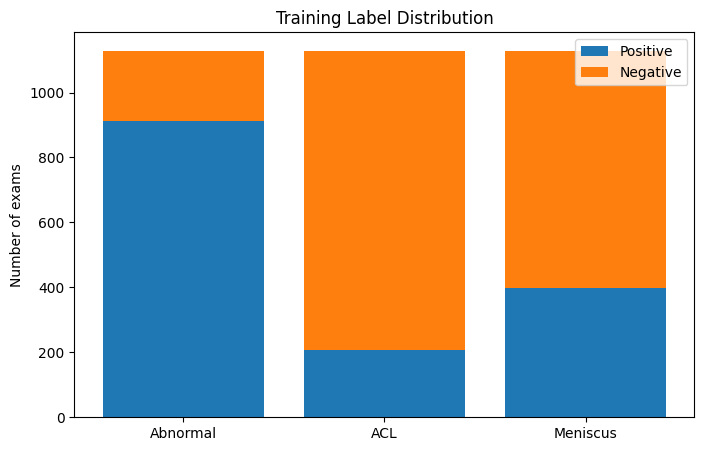

In [ ]:
import matplotlib.pyplot as plt

positive_counts = [
    labels["abnormal"].sum(),
    labels["acl"].sum(),
    labels["meniscus"].sum()
]

negative_counts = [
    (labels["abnormal"] == 0).sum(),
    (labels["acl"] == 0).sum(),
    (labels["meniscus"] == 0).sum()
]

x = ["Abnormal", "ACL", "Meniscus"]

plt.figure(figsize=(8, 5))

plt.bar(x, positive_counts, label="Positive")
plt.bar(
    x,
    negative_counts,
    bottom=positive_counts,
    label="Negative"
)

plt.ylabel("Number of exams")
plt.title("Training Label Distribution")
plt.legend()

plt.show()

## 4 · File structure

Each exam has one .npy volume per view (sagittal, coronal, axial).

In [ ]:
train_files["exam_id"] = (
    train_files["file_name"]
    .str.extract(r"/(?P<exam_id>\d+)\.npy", expand=False)
)

train_files["view"] = (
    train_files["file_name"]
    .str.extract(r"(?P<view>[^/]+)/\d+\.npy", expand=False)
)

display(
    train_files[["file_name", "exam_id", "view"]].head(10)
)

,file_name,exam_id,view
0,sagittal/0060.npy,0060,sagittal
1,sagittal/0027.npy,0027,sagittal
2,sagittal/0053.npy,0053,sagittal
3,sagittal/0014.npy,0014,sagittal
4,sagittal/0046.npy,0046,sagittal
5,sagittal/0018.npy,0018,sagittal
6,sagittal/0071.npy,0071,sagittal
7,sagittal/0069.npy,0069,sagittal
8,sagittal/0058.npy,0058,sagittal
9,sagittal/0062.npy,0062,sagittal


In [ ]:
print(train_files["view"].value_counts())

view
sagittal    1130
coronal     1130
axial       1130
Name: count, dtype: int64[pyarrow]


In [ ]:
print("Total MRI files:", len(train_files))
print("Unique exams:", train_files["exam_id"].nunique())

Total MRI files: 3390
Unique exams: 1130


## 5 · Volume inspection

Load a single volume and visualise the middle slice for each view.

In [ ]:
from io import BytesIO
import numpy as np

example_file = dataset.table("train").file("sagittal/0060.npy")

data = example_file.read()

mri = np.load(BytesIO(data))

print("Shape:", mri.shape)
print("Data type:", mri.dtype)
print("Minimum value:", mri.min())
print("Maximum value:", mri.max())

Please delete the token on Redivis and remove it from your code, and follow the authentication prompts here instead.

This environment variable should only ever be set in a non-interactive environment, such as in an automated script or service.

Shape: (18, 256, 256)
Data type: uint8
Minimum value: 0
Maximum value: 255


In [ ]:
print("Number of slices:", mri.shape[0])
print("Image height:", mri.shape[1])
print("Image width:", mri.shape[2])

Number of slices: 18
Image height: 256
Image width: 256


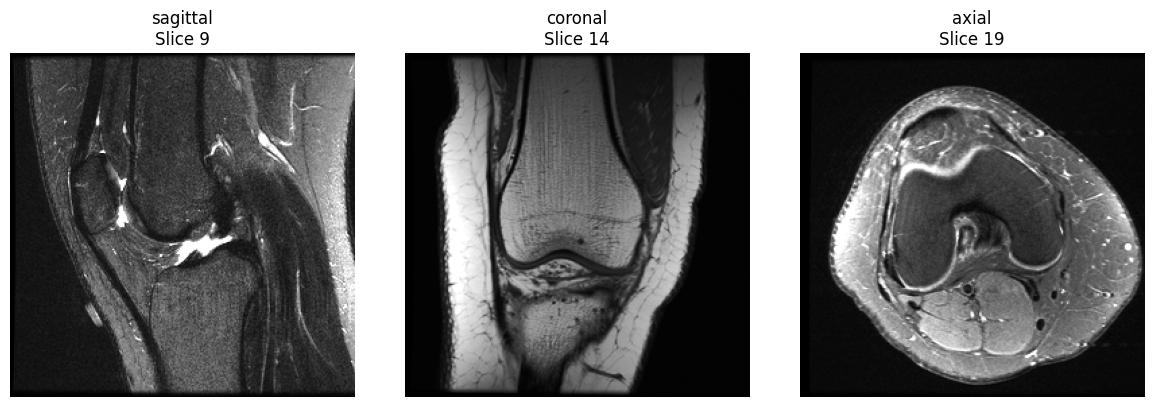

In [ ]:
example_exam = "0060"

views = ["sagittal", "coronal", "axial"]

plt.figure(figsize=(12, 4))

for i, view in enumerate(views):

    filename = f"{view}/{example_exam}.npy"

    f = dataset.table("train").file(filename)

    volume = np.load(BytesIO(f.read()))

    middle_slice = volume.shape[0] // 2

    plt.subplot(1, 3, i + 1)

    plt.imshow(
        volume[middle_slice],
        cmap="gray"
    )

    plt.title(f"{view}\nSlice {middle_slice}")
    plt.axis("off")

plt.tight_layout()
plt.show()

## 6 · Slice statistics

Sample 30 exams per view to characterise the variable slice counts.

In [ ]:
from io import BytesIO
import numpy as np
import pandas as pd


sample_files = (
    train_files
    .groupby("view", group_keys=False)
    .head(30)
)

print("Files being sampled:", len(sample_files))
print(sample_files["view"].value_counts())

slice_counts = []

for _, row in sample_files.iterrows():

    f = dataset.table("train").file(row["file_name"])
    volume = np.load(BytesIO(f.read()))

    slice_counts.append({
        "exam_id": row["exam_id"],
        "view": row["view"],
        "num_slices": volume.shape[0],
        "height": volume.shape[1],
        "width": volume.shape[2]
    })

slice_info = pd.DataFrame(slice_counts)

display(slice_info.head())

Files being sampled: 90
view
sagittal    30
coronal     30
axial       30
Name: count, dtype: int64[pyarrow]
Please delete the token on Redivis and remove it from your code, and follow the authentication prompts here instead.

This environment variable should only ever be set in a non-interactive environment, such as in an automated script or service.



,exam_id,view,num_slices,height,width
0,0060,sagittal,18,256,256
1,0027,sagittal,19,256,256
2,0053,sagittal,19,256,256
3,0014,sagittal,20,256,256
4,0046,sagittal,20,256,256


In [ ]:
print("Slice statistics by view:")

display(
    slice_info
    .groupby("view")["num_slices"]
    .describe()
)

Slice statistics by view:


,count,mean,std,min,25%,50%,75%,max
view,,,,,,,,
axial,30.0,23.833333,2.587548,19.0,22.25,24.0,26.0,28.0
coronal,30.0,18.133333,0.776079,17.0,18.00,18.0,19.0,20.0
sagittal,30.0,24.266667,3.139661,18.0,22.00,24.0,26.0,30.0


In [ ]:
print("Image dimensions:")

display(
    slice_info
    .groupby(["view", "height", "width"])
    .size()
)

Image dimensions:


,,,0
view,height,width,
axial,256,256,30
coronal,256,256,30
sagittal,256,256,30


---
## 7 · Baseline model

**Architecture:** Frozen ImageNet ResNet18 → mean pooling across slices → Linear(512, 3)  
**View used:** sagittal only  
**Loss:** BCEWithLogitsLoss with positive-class weights  
**Optimiser:** Adam

### 7a · Config & reproducibility

In [ ]:
import random
import numpy as np
import pandas as pd
import torch

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

MAX_TRAIN_EXAMS = None
MAX_VALID_EXAMS = None
EPOCHS = 3
LEARNING_RATE = 1e-3
CACHE_ROOT = "/content/mrnet_cache"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


### 7b · Data loading & label alignment

In [ ]:
from IPython.display import display


train_files = dataset.table("train").to_pandas_dataframe()
valid_files = dataset.table("valid").to_pandas_dataframe()

def normalize_exam_ids(series):

    return (
        series.astype("string")
        .str.replace(r"\.0$", "", regex=True)
        .str.zfill(4)
    )

def add_exam_and_view_columns(files):
    files = files.copy()
    files["exam_id"] = normalize_exam_ids(
        files["file_name"].str.extract(r"/(?P<exam_id>\d+)\.npy", expand=False)
    )
    files["view"] = files["file_name"].str.extract(
        r"(?P<view>[^/]+)/\d+\.npy", expand=False
    )
    return files

train_files = add_exam_and_view_columns(train_files)
valid_files = add_exam_and_view_columns(valid_files)


def load_labels(split):
    abnormal = dataset.table(f"{split}_abnormal").to_pandas_dataframe()
    acl = dataset.table(f"{split}_acl").to_pandas_dataframe()
    meniscus = dataset.table(f"{split}_meniscus").to_pandas_dataframe()

    abnormal.columns = ["exam_id", "abnormal"]
    acl.columns = ["exam_id", "acl"]
    meniscus.columns = ["exam_id", "meniscus"]

    combined = abnormal.merge(acl, on="exam_id").merge(meniscus, on="exam_id")
    combined["exam_id"] = normalize_exam_ids(combined["exam_id"])

    for col in ["abnormal", "acl", "meniscus"]:
        combined[col] = pd.to_numeric(combined[col]).astype("float32")

    return combined

train_labels = load_labels("train")
valid_labels = load_labels("valid")

def make_exam_table(files, labels):
    sagittal = files.loc[files["view"] == "sagittal", ["exam_id", "file_name"]]
    sagittal = sagittal.rename(columns={"file_name": "sagittal_file"})

    exams = sagittal.merge(labels, on="exam_id", how="inner")
    return exams.drop_duplicates("exam_id").reset_index(drop=True)

train_exams = make_exam_table(train_files, train_labels)
valid_exams = make_exam_table(valid_files, valid_labels)

train_file_ids = set(train_files["exam_id"].dropna())
valid_file_ids = set(valid_files["exam_id"].dropna())
train_label_ids = set(train_labels["exam_id"])
valid_label_ids = set(valid_labels["exam_id"])

print("Training files:", len(train_files), "| exams with labels:", len(train_exams))
print("Validation files:", len(valid_files), "| exams with labels:", len(valid_exams))
print("Training exams missing labels:", sorted(train_file_ids - train_label_ids))
print("Validation exams missing labels:", sorted(valid_file_ids - valid_label_ids))
print("Train/validation exam overlap:", len(set(train_exams["exam_id"]) & set(valid_exams["exam_id"])))

display(train_exams.head())

Please delete the token on Redivis and remove it from your code, and follow the authentication prompts here instead.

This environment variable should only ever be set in a non-interactive environment, such as in an automated script or service.



  0%|          | 0/3390 [00:00<?, ?it/s]

  0%|          | 0/360 [00:00<?, ?it/s]

Please delete the token on Redivis and remove it from your code, and follow the authentication prompts here instead.

This environment variable should only ever be set in a non-interactive environment, such as in an automated script or service.



  0%|          | 0/1129 [00:00<?, ?it/s]

  0%|          | 0/1129 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/119 [00:00<?, ?it/s]

  0%|          | 0/119 [00:00<?, ?it/s]

Training files: 3390 | exams with labels: 1129
Validation files: 360 | exams with labels: 119
Training exams missing labels: ['0000']
Validation exams missing labels: ['1130']
Train/validation exam overlap: 0


,exam_id,sagittal_file,abnormal,acl,meniscus
0,0060,sagittal/0060.npy,0.0,0.0,0.0
1,0027,sagittal/0027.npy,1.0,0.0,1.0
2,0053,sagittal/0053.npy,0.0,0.0,0.0
3,0014,sagittal/0014.npy,0.0,0.0,0.0
4,0046,sagittal/0046.npy,1.0,1.0,0.0


In [ ]:
if MAX_TRAIN_EXAMS is not None and len(train_exams) > MAX_TRAIN_EXAMS:
    train_run = train_exams.sample(n=MAX_TRAIN_EXAMS, random_state=SEED).reset_index(drop=True)
else:
    train_run = train_exams.copy().reset_index(drop=True)

if MAX_VALID_EXAMS is not None and len(valid_exams) > MAX_VALID_EXAMS:
    valid_run = valid_exams.sample(n=MAX_VALID_EXAMS, random_state=SEED).reset_index(drop=True)
else:
    valid_run = valid_exams.copy().reset_index(drop=True)

print(f"Run subset: {len(train_run)} training exams, {len(valid_run)} validation exams")
print("\nTraining positive-label rates:")
display(train_run[["abnormal", "acl", "meniscus"]].mean().rename("positive_fraction"))

Run subset: 1129 training exams, 119 validation exams

Training positive-label rates:


,positive_fraction
abnormal,0.807795
acl,0.184234
meniscus,0.351639


### 7c · Cache volumes to disk

In [ ]:
from io import BytesIO
from pathlib import Path
from tqdm.auto import tqdm

def cache_split(exams, split):
    cache_dir = Path(CACHE_ROOT) / split
    cache_dir.mkdir(parents=True, exist_ok=True)
    table = dataset.table("train" if split == "train" else "valid")

    for row in tqdm(exams.itertuples(index=False), total=len(exams), desc=f"Caching {split}"):
        destination = cache_dir / f"{row.exam_id}.npy"
        if destination.exists():
            continue

        file_obj = table.file(row.sagittal_file)
        raw = file_obj.read()
        volume = np.load(BytesIO(raw))

        if volume.ndim != 3:
            raise ValueError(f"Expected a 3D volume for {row.exam_id}, got shape {volume.shape}")

        np.save(destination, volume)

    return cache_dir

train_cache = cache_split(train_run, "train")
valid_cache = cache_split(valid_run, "valid")

print("Cached training volumes:", len(list(train_cache.glob("*.npy"))))
print("Cached validation volumes:", len(list(valid_cache.glob("*.npy"))))

Caching train:   0%|          | 0/1129 [00:00<?, ?it/s]

Please delete the token on Redivis and remove it from your code, and follow the authentication prompts here instead.

This environment variable should only ever be set in a non-interactive environment, such as in an automated script or service.



Caching valid:   0%|          | 0/119 [00:00<?, ?it/s]

Cached training volumes: 1129
Cached validation volumes: 119


### 7d · Dataset & DataLoader

In [ ]:
from torch.utils.data import Dataset, DataLoader

LABEL_COLUMNS = ["abnormal", "acl", "meniscus"]

class KneeMRIDataset(Dataset):
    def __init__(self, exams, cache_dir):
        self.exams = exams.reset_index(drop=True)
        self.cache_dir = Path(cache_dir)

    def __len__(self):
        return len(self.exams)

    def __getitem__(self, index):
        row = self.exams.iloc[index]
        volume_path = self.cache_dir / f"{row['exam_id']}.npy"
        volume = np.load(volume_path).astype(np.float32) / 255.0
        labels = row[LABEL_COLUMNS].to_numpy(dtype=np.float32)

        return torch.from_numpy(volume), torch.tensor(labels), row["exam_id"]

train_ds = KneeMRIDataset(train_run, train_cache)
valid_ds = KneeMRIDataset(valid_run, valid_cache)

train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, num_workers=0)
valid_loader = DataLoader(valid_ds, batch_size=1, shuffle=False, num_workers=0)

volume, target, exam_id = train_ds[0]
print("Example exam:", exam_id)
print("Volume tensor shape (slices, height, width):", tuple(volume.shape))
print("Labels [abnormal, ACL, meniscus]:", target.tolist())

Example exam: 0060
Volume tensor shape (slices, height, width): (18, 256, 256)
Labels [abnormal, ACL, meniscus]: [0.0, 0.0, 0.0]


### 7e · Model definition

In [ ]:
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18, ResNet18_Weights

class ResNetMeanPool(nn.Module):
    def __init__(self):
        super().__init__()
        weights = ResNet18_Weights.DEFAULT
        backbone = resnet18(weights=weights)
        self.encoder = nn.Sequential(*list(backbone.children())[:-1])  # output: 512 features
        for param in self.encoder.parameters():
            param.requires_grad = False
        self.encoder.eval()

        self.classifier = nn.Linear(512, 3)

        # ImageNet normalization for the pretrained encoder
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std", torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))

    def train(self, mode=True):
        super().train(mode)
        self.encoder.eval()  # keep frozen backbone/batchnorm in eval mode
        return self

    def forward(self, volume):
        # volume shape: (N, H, W), values in [0, 1]
        x = volume.unsqueeze(1)                         # (N, 1, H, W)
        x = F.interpolate(x, size=(224, 224), mode="bilinear", align_corners=False)
        x = x.repeat(1, 3, 1, 1)                       # pretrained ResNet expects RGB
        x = (x - self.mean) / self.std

        features = []
        with torch.no_grad():
            for start in range(0, x.shape[0], 8):      # process slices in small chunks
                batch = x[start:start + 8]
                feat = self.encoder(batch).flatten(1)  # (chunk_slices, 512)
                features.append(feat)

        features = torch.cat(features, dim=0)
        exam_feature = features.mean(dim=0)            # mean pooling across slices
        logits = self.classifier(exam_feature)         # three raw logits
        return logits

model = ResNetMeanPool().to(device)
print(model.__class__.__name__)
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

ResNetMeanPool
Trainable parameters: 1539


### 7f · Training loop

In [ ]:

y_train = train_run[LABEL_COLUMNS].to_numpy(dtype=np.float32)
positive = y_train.sum(axis=0)
negative = len(y_train) - positive
pos_weight = negative / np.maximum(positive, 1.0)
pos_weight = torch.tensor(pos_weight, dtype=torch.float32, device=device)

criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight)
optimizer = torch.optim.Adam(model.classifier.parameters(), lr=LEARNING_RATE)

history = []

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0.0

    for volume, target, _exam_id in tqdm(train_loader, desc=f"Epoch {epoch+1}/{EPOCHS}"):
        volume = volume.squeeze(0).to(device)   # (N, H, W)
        target = target.squeeze(0).to(device)   # (3,)

        optimizer.zero_grad()
        logits = model(volume)
        loss = criterion(logits, target)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    mean_loss = total_loss / max(len(train_loader), 1)
    history.append(mean_loss)
    print(f"Epoch {epoch+1}/{EPOCHS} — training loss: {mean_loss:.4f}")

print("Training complete.")

Epoch 1/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 1/3 — training loss: 0.7546


Epoch 2/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 2/3 — training loss: 0.6820


Epoch 3/3:   0%|          | 0/1129 [00:00<?, ?it/s]

Epoch 3/3 — training loss: 0.6664
Training complete.


### 7g · Evaluation

In [ ]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score, accuracy_score,
    precision_score, recall_score, f1_score
)

model.eval()
all_targets = []
all_probs = []
all_ids = []

with torch.no_grad():
    for volume, target, exam_id in tqdm(valid_loader, desc="Validation"):
        volume = volume.squeeze(0).to(device)
        logits = model(volume)
        probs = torch.sigmoid(logits).cpu().numpy()

        all_targets.append(target.squeeze(0).numpy())
        all_probs.append(probs)
        all_ids.append(exam_id[0])

y_true = np.asarray(all_targets)
y_prob = np.asarray(all_probs)
y_pred = (y_prob >= 0.5).astype(int)

rows = []
for j, label in enumerate(LABEL_COLUMNS):
    if len(np.unique(y_true[:, j])) == 2:
        auc = roc_auc_score(y_true[:, j], y_prob[:, j])
    else:
        auc = np.nan

    if y_true[:, j].sum() > 0:
        ap = average_precision_score(y_true[:, j], y_prob[:, j])
    else:
        ap = np.nan

    rows.append({
        "label": label,
        "ROC_AUC": auc,
        "Average_Precision": ap,
        "Accuracy@0.5": accuracy_score(y_true[:, j], y_pred[:, j]),
        "Precision@0.5": precision_score(y_true[:, j], y_pred[:, j], zero_division=0),
        "Recall@0.5": recall_score(y_true[:, j], y_pred[:, j], zero_division=0),
        "F1@0.5": f1_score(y_true[:, j], y_pred[:, j], zero_division=0),
    })

metrics_df = pd.DataFrame(rows)
display(metrics_df.round(3))

print("Note: these are preliminary subset metrics, not final results.")

Validation:   0%|          | 0/119 [00:00<?, ?it/s]

,label,ROC_AUC,Average_Precision,Accuracy@0.5,Precision@0.5,Recall@0.5,F1@0.5
0,abnormal,0.897,0.974,0.824,0.843,0.958,0.897
1,acl,0.891,0.870,0.714,0.622,0.944,0.750
2,meniscus,0.747,0.682,0.664,0.588,0.769,0.667


Note: these are preliminary subset metrics, not final results.


In [ ]:
predictions_df = pd.DataFrame({
    "exam_id": all_ids,
    "true_abnormal": y_true[:, 0].astype(int),
    "pred_abnormal_prob": y_prob[:, 0],
    "true_acl": y_true[:, 1].astype(int),
    "pred_acl_prob": y_prob[:, 1],
    "true_meniscus": y_true[:, 2].astype(int),
    "pred_meniscus_prob": y_prob[:, 2],
})

display(predictions_df.head(10).round(3))

,exam_id,true_abnormal,pred_abnormal_prob,true_acl,pred_acl_prob,true_meniscus,pred_meniscus_prob
0,1185,1,0.797,1,0.742,0,0.304
1,1242,1,0.983,0,0.917,1,0.750
2,1133,0,0.296,0,0.409,0,0.118
3,1249,1,0.467,0,0.331,1,0.114
4,1148,0,0.551,0,0.448,0,0.172
5,1228,1,0.938,1,0.938,1,0.609
6,1152,0,0.408,0,0.177,0,0.103
7,1164,1,0.445,0,0.749,0,0.307
8,1200,1,0.415,1,0.803,0,0.289
9,1138,0,0.149,0,0.638,0,0.121


### 7h · Results

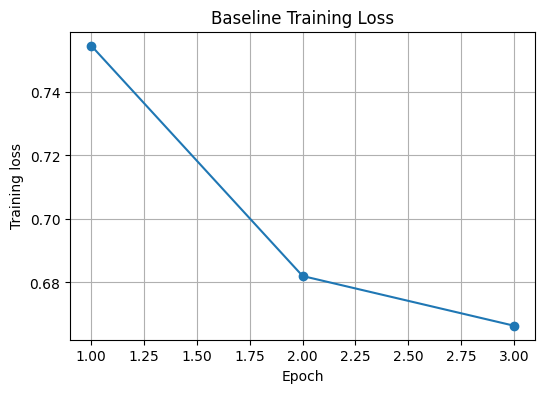

Saved checkpoint to: /content/mrnet_resnet18_meanpool_baseline.pt


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.plot(range(1, len(history) + 1), history, marker="o")
plt.xlabel("Epoch")
plt.ylabel("Training loss")
plt.title("Baseline Training Loss")
plt.grid(True)
plt.show()

checkpoint_path = "/content/mrnet_resnet18_meanpool_baseline.pt"
torch.save({
    "model_state_dict": model.state_dict(),
    "label_columns": LABEL_COLUMNS,
    "architecture": "ImageNet ResNet18 frozen encoder + mean slice pooling + linear 3-label head",
    "epochs": EPOCHS,
    "seed": SEED,
}, checkpoint_path)

print("Saved checkpoint to:", checkpoint_path)